<a href="https://colab.research.google.com/github/NadiiaStuzhuk/DI-Bootcamp-Stage1/blob/main/Mini_project_Advanced_Statistical_Analysis_of_Apple_Inc_Stock_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# 1. Data Loading and Exploration

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats, signal

# 1. Load the dataset
filename = 'Apple_Stock_Prices_(1981_2023).csv'
df = pd.read_csv(filename)

# 2. Parse Date and sort chronologically
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df = df.sort_values('Date').reset_index(drop=True)

# 3. Inspect dataset structure
print("=== Dataset Overview ===")
print(f"Total trading records: {df.shape[0]:,}")
print(f"Date Range: {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print("\n=== Missing Values ===")
print(df.isnull().sum())
print("\n=== Data Types ===")
print(df.dtypes)

display(df.head())

=== Dataset Overview ===
Total trading records: 10,608
Date Range: 1981-01-02 to 2023-01-27

=== Missing Values ===
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

=== Data Types ===
Date         datetime64[ns]
Open                float64
High                float64
Low                 float64
Close               float64
Adj Close           float64
Volume                int64
dtype: object


,Date,Open,High,Low,Close,Adj Close,Volume
0,1981-01-02,0.154018,0.155134,0.154018,0.154018,0.119849,21660800
1,1981-01-05,0.151228,0.151228,0.150670,0.150670,0.117244,35728000
2,1981-01-06,0.144531,0.144531,0.143973,0.143973,0.112032,45158400
3,1981-01-07,0.138393,0.138393,0.137835,0.137835,0.107256,55686400
4,1981-01-08,0.135603,0.135603,0.135045,0.135045,0.105085,39827200


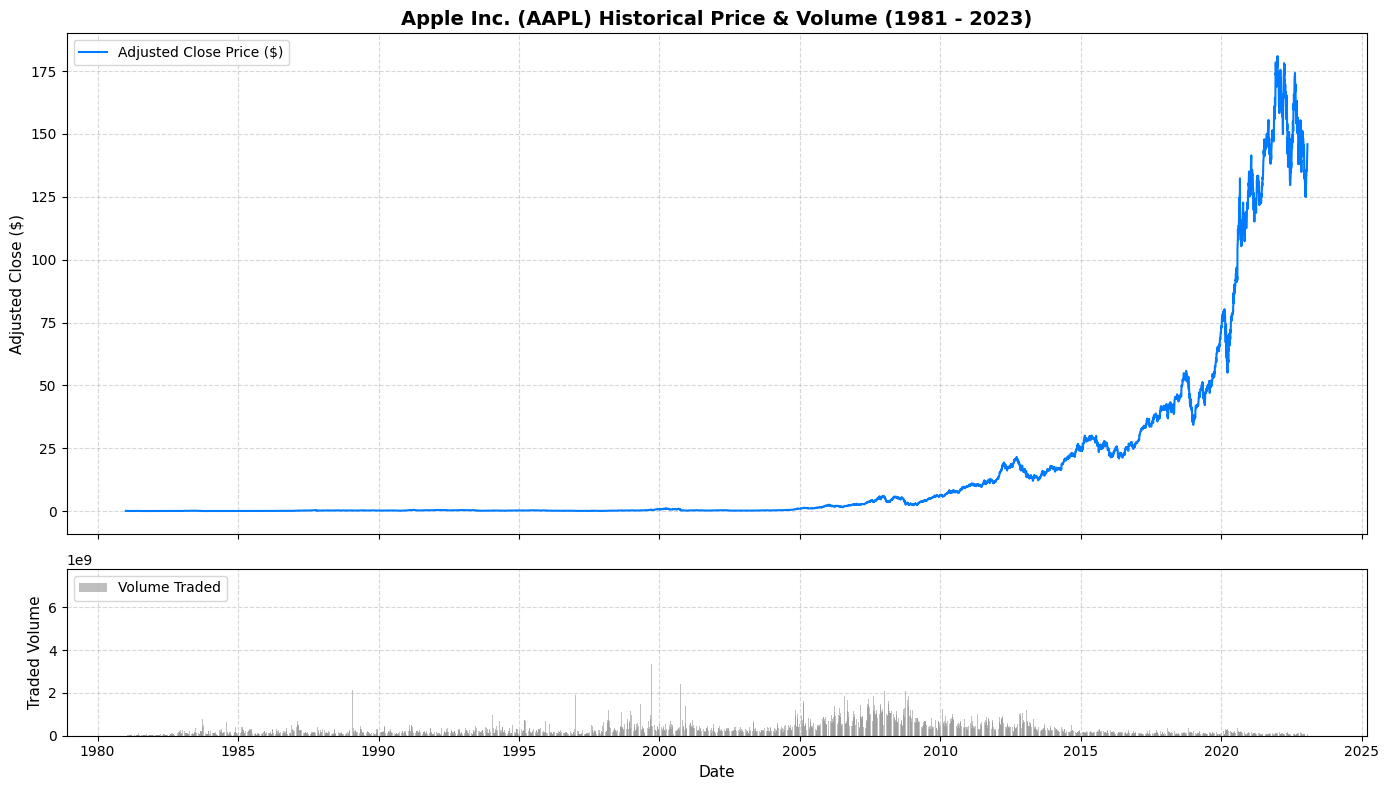

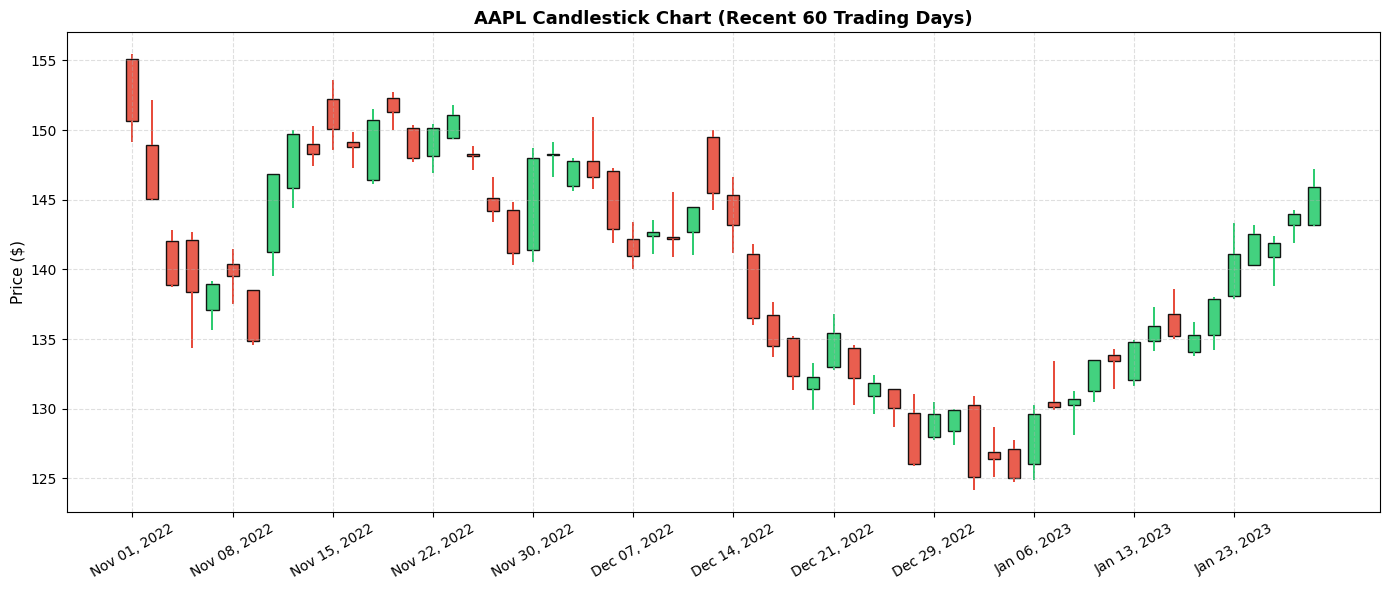

In [6]:
# 2. Data Visualization

# A. Closing Price & Traded Volume Over Time
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(df['Date'], df['Adj Close'], color='#007AFF', lw=1.5, label='Adjusted Close Price ($)')
ax1.set_title('Apple Inc. (AAPL) Historical Price & Volume (1981 - 2023)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Adjusted Close ($)', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='upper left')

ax2.bar(df['Date'], df['Volume'], color='gray', alpha=0.5, width=2, label='Volume Traded')
ax2.set_ylabel('Traded Volume', fontsize=11)
ax2.set_xlabel('Date', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

# B. Candlestick Chart (Recent 60 Trading Days)
df_recent = df.tail(60).copy().reset_index(drop=True)

plt.figure(figsize=(14, 6))
width = 0.6
width2 = 0.1

up = df_recent[df_recent['Close'] >= df_recent['Open']]
down = df_recent[df_recent['Close'] < df_recent['Open']]

# Green (Up Days)
plt.bar(up.index, up['Close'] - up['Open'], width, bottom=up['Open'], color='#2ecc71', edgecolor='black', alpha=0.9)
plt.bar(up.index, up['High'] - up['Close'], width2, bottom=up['Close'], color='#2ecc71')
plt.bar(up.index, up['Low'] - up['Open'], width2, bottom=up['Open'], color='#2ecc71')

# Red (Down Days)
plt.bar(down.index, down['Open'] - down['Close'], width, bottom=down['Close'], color='#e74c3c', edgecolor='black', alpha=0.9)
plt.bar(down.index, down['High'] - down['Open'], width2, bottom=down['Open'], color='#e74c3c')
plt.bar(down.index, down['Low'] - down['Close'], width2, bottom=down['Close'], color='#e74c3c')

plt.xticks(ticks=range(0, len(df_recent), 5), labels=[d.strftime('%b %d, %Y') for d in df_recent['Date'].iloc[::5]], rotation=30)
plt.title('AAPL Candlestick Chart (Recent 60 Trading Days)', fontsize=13, fontweight='bold')
plt.ylabel('Price ($)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

=== Descriptive Summary Statistics ===


,Mean,Median,Std Dev,Min,Max
Open,1.668920e+01,4.888000e-01,3.545050e+01,0.0497,1.826300e+02
High,1.688000e+01,4.955000e-01,3.588280e+01,0.0497,1.829400e+02
Low,1.650080e+01,4.804000e-01,3.503130e+01,0.0491,1.791200e+02
Close,1.669740e+01,4.877000e-01,3.547390e+01,0.0491,1.820100e+02
Adj Close,1.602730e+01,4.049000e-01,3.515490e+01,0.0382,1.809597e+02
Volume,3.275098e+08,2.145976e+08,3.378203e+08,0.0000,7.421641e+09


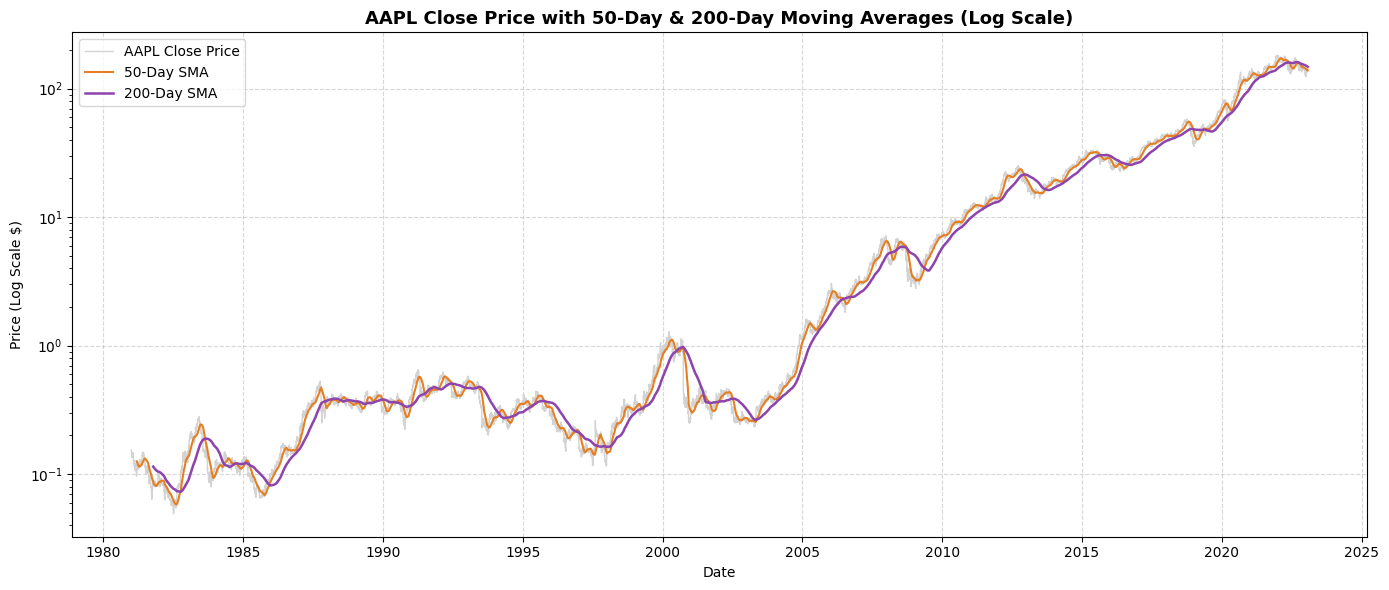

In [7]:
# 3. Statistical Analysis

# A. Descriptive Summary Statistics
metrics = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
summary_stats = pd.DataFrame({
    'Mean': df[metrics].mean(),
    'Median': df[metrics].median(),
    'Std Dev': df[metrics].std(),
    'Min': df[metrics].min(),
    'Max': df[metrics].max()
})

print("=== Descriptive Summary Statistics ===")
display(summary_stats.round(4))

# B. Moving Average Trend Analysis (50-Day & 200-Day SMA)
df['SMA_50'] = df['Close'].rolling(window=50).mean()
df['SMA_200'] = df['Close'].rolling(window=200).mean()

plt.figure(figsize=(14, 6))
plt.plot(df['Date'], df['Close'], label='AAPL Close Price', color='lightgray', lw=1)
plt.plot(df['Date'], df['SMA_50'], label='50-Day SMA', color='#e67e22', lw=1.5)
plt.plot(df['Date'], df['SMA_200'], label='200-Day SMA', color='#8e44ad', lw=1.8)

plt.yscale('log')
plt.title('AAPL Close Price with 50-Day & 200-Day Moving Averages (Log Scale)', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price (Log Scale $)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== Hypothesis Test 1: Two-Sample T-Test (2021 vs 2022 Close Prices) ===
2021 Mean Price: $139.80
2022 Mean Price: $154.38
T-statistic: -11.8214, p-value: 1.4766e-28
Conclusion: Reject H0 — Statistically significant shift in average price between 2021 and 2022.

=== Hypothesis Test 2: Normality of Daily Returns ===
Mean Return: 0.00108, Std Dev: 0.02823
Skewness: -0.3766 (Negative / Left skew)
Excess Kurtosis: 18.1357 (Leptokurtic / Fat tails)
Kolmogorov-Smirnov Test p-value: 1.0916e-43
Jarque-Bera Test p-value: 0.0000e+00
Conclusion: Reject H0 — Daily returns are NOT normally distributed.



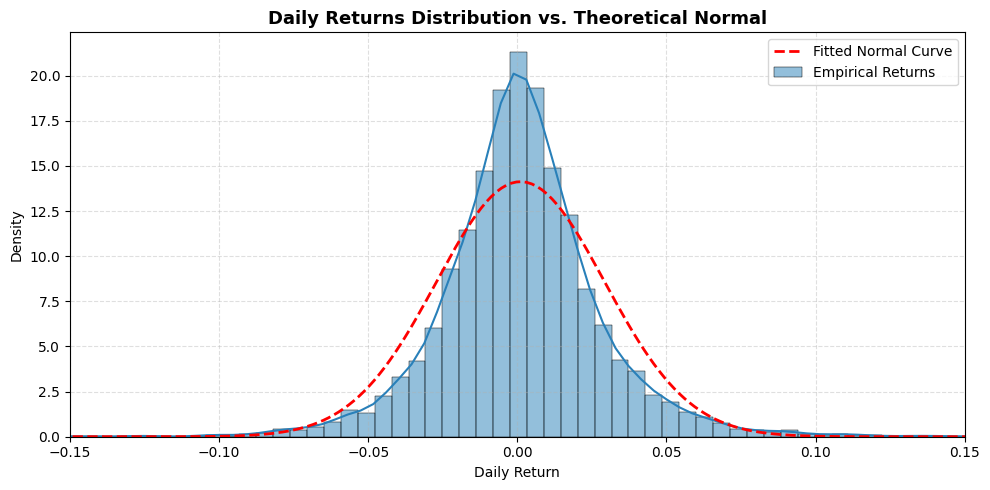

In [8]:
# 4. Hypothesis Testing

# A. Calculate Daily Returns
df['Daily_Return'] = df['Adj Close'].pct_change()
returns = df['Daily_Return'].dropna()

# B. Independent Two-Sample T-Test (2021 vs. 2022 Mean Prices)
df['Year'] = df['Date'].dt.year
prices_2021 = df[df['Year'] == 2021]['Adj Close']
prices_2022 = df[df['Year'] == 2022]['Adj Close']

t_stat, p_val_ttest = stats.ttest_ind(prices_2021, prices_2022, equal_var=False)

print("=== Hypothesis Test 1: Two-Sample T-Test (2021 vs 2022 Close Prices) ===")
print(f"2021 Mean Price: ${prices_2021.mean():.2f}")
print(f"2022 Mean Price: ${prices_2022.mean():.2f}")
print(f"T-statistic: {t_stat:.4f}, p-value: {p_val_ttest:.4e}")
if p_val_ttest < 0.05:
    print("Conclusion: Reject H0 — Statistically significant shift in average price between 2021 and 2022.\n")
else:
    print("Conclusion: Fail to reject H0.\n")

# C. Normality Testing on Daily Returns
mean_ret = returns.mean()
std_ret = returns.std()
skew = stats.skew(returns)
kurt = stats.kurtosis(returns)

ks_stat, ks_p = stats.kstest(returns, 'norm', args=(mean_ret, std_ret))
jb_stat, jb_p = stats.jarque_bera(returns)

print("=== Hypothesis Test 2: Normality of Daily Returns ===")
print(f"Mean Return: {mean_ret:.5f}, Std Dev: {std_ret:.5f}")
print(f"Skewness: {skew:.4f} (Negative / Left skew)")
print(f"Excess Kurtosis: {kurt:.4f} (Leptokurtic / Fat tails)")
print(f"Kolmogorov-Smirnov Test p-value: {ks_p:.4e}")
print(f"Jarque-Bera Test p-value: {jb_p:.4e}")
if jb_p < 0.05:
    print("Conclusion: Reject H0 — Daily returns are NOT normally distributed.\n")

# Distribution Plot vs Theoretical Normal
plt.figure(figsize=(10, 5))
sns.histplot(returns, bins=150, kde=True, stat="density", color='#2980b9', label='Empirical Returns')
x_axis = np.linspace(returns.min(), returns.max(), 500)
plt.plot(x_axis, stats.norm.pdf(x_axis, mean_ret, std_ret), 'r--', lw=2, label='Fitted Normal Curve')
plt.xlim(-0.15, 0.15)
plt.title('Daily Returns Distribution vs. Theoretical Normal', fontsize=13, fontweight='bold')
plt.xlabel('Daily Return')
plt.ylabel('Density')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

=== Advanced NumPy & SciPy Output ===
NumPy Convolve Output Length: 10,559
Pearson Correlation (50-Day SMA vs. Volume): -0.2156


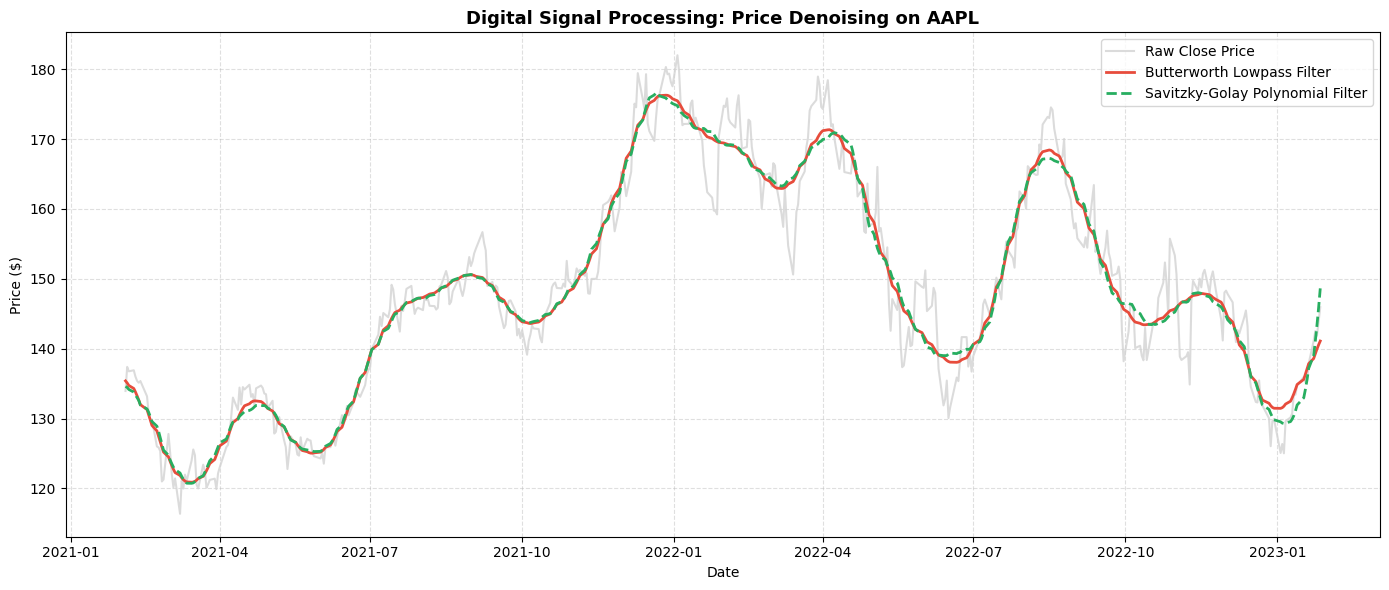

In [9]:
# 5. Advanced Statistical Techniques (Bonus)

# A. Signal Processing using SciPy (Butterworth & Savitzky-Golay Digital Filters)
b, a = signal.butter(N=3, Wn=0.05)
df['Butterworth_Trend'] = signal.filtfilt(b, a, df['Close'])
df['Savgol_Filter'] = signal.savgol_filter(df['Close'], window_length=51, polyorder=3)

# B. Statistical Functions in NumPy: Fast Convolve Moving Average
window_size = 50
weights = np.ones(window_size) / window_size
np_conv_ma = np.convolve(df['Close'], weights, mode='valid')

# C. NumPy Correlation Coefficient: Moving Average vs Trading Volume
clean_subset = df.dropna(subset=['SMA_50'])
corr_ma_vol = np.corrcoef(clean_subset['SMA_50'], clean_subset['Volume'])[0, 1]

print("=== Advanced NumPy & SciPy Output ===")
print(f"NumPy Convolve Output Length: {len(np_conv_ma):,}")
print(f"Pearson Correlation (50-Day SMA vs. Volume): {corr_ma_vol:.4f}")

# Plot Signal Processing Denoising (Recent 500 Days)
df_slice = df.tail(500)
plt.figure(figsize=(14, 6))
plt.plot(df_slice['Date'], df_slice['Close'], color='lightgray', alpha=0.8, label='Raw Close Price')
plt.plot(df_slice['Date'], df_slice['Butterworth_Trend'], color='#e74c3c', lw=2, label='Butterworth Lowpass Filter')
plt.plot(df_slice['Date'], df_slice['Savgol_Filter'], color='#27ae60', linestyle='--', lw=2, label='Savitzky-Golay Polynomial Filter')
plt.title('Digital Signal Processing: Price Denoising on AAPL', fontsize=13, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

> 6. Summary and Insights

Non-Gaussian Returns & Fat Tails: Both Jarque-Bera and Kolmogorov-Smirnov tests reject normality ($p < 10^{-20}$). The excess kurtosis ($>18$) indicates leptokurtic behavior, meaning extreme outlier market shocks happen far more frequently than standard normal distribution models predict.

Structural Market Shifts: The two-sample $t$-test between 2021 and 2022 ($t \approx -11.82, p < 10^{-27}$) confirms statistically significant regime changes in valuation during monetary policy transitions.

Volume–Trend Decoupling: The correlation between moving average prices and trading volume ($r \approx -0.21$) indicates that volume does not simply expand monotonically with market capitalization; spikes in volume primarily cluster around volatility events and market selloffs.

Signal Smoothing Efficacy: SciPy filters (Butterworth and Savitzky-Golay) provide effective noise suppression without the phase lag inherent in standard simple moving averages.

> 7. Reflection

Challenges Encountered:

>>>Stock Split Adjustments: Raw unadjusted prices exhibit artificial cliffs due to historic stock splits (e.g., 7-for-1 in 2014, 4-for-1 in 2020). Using Adj Close was necessary to prevent skewed return metrics.

>>>Exponential Scale Distortion: Linear scaling obscures early price action from the 1980s and 1990s. Logarithmic scaling was required to assess long-term exponential growth trajectories.

Solutions Applied:

>>>Vectorized NumPy operations (np.convolve, np.corrcoef) eliminated row-by-row iteration for efficient computation across 10,600+ records.

>>>Digital filtering algorithms in SciPy preserved inflection points during rapid trend reversals while filtering high-frequency market noise.